In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

          x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
0 -1.000000  11.624419   8.296963  12.201067   7.811725   3.155566
1 -0.929293  10.377466   9.674440  12.198084   8.275006   7.518855
2 -0.858586  10.585100   9.251983  13.186565  12.926586   9.963630
3 -0.787879  10.913928   7.786344  12.552304  11.832379   9.625801
4 -0.717172   8.640287   8.551869   4.741432   8.790834   6.624113            x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
95  5.717172  -1.411918   0.822231  -2.027132  -1.825106   2.746147
96  5.787879   0.344879  -1.718956   2.747559  -6.803779  -5.137472
97  5.858586   0.307133   0.353528   0.967976   5.461567  -0.905616
98  5.929293   0.048657   0.159961   2.482130  -0.414616  -4.334548
99  6.000000  -0.193438  -2.244792   1.930035   4.992414  -6.872850


/tmp/ipykernel_10240/2981488622.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


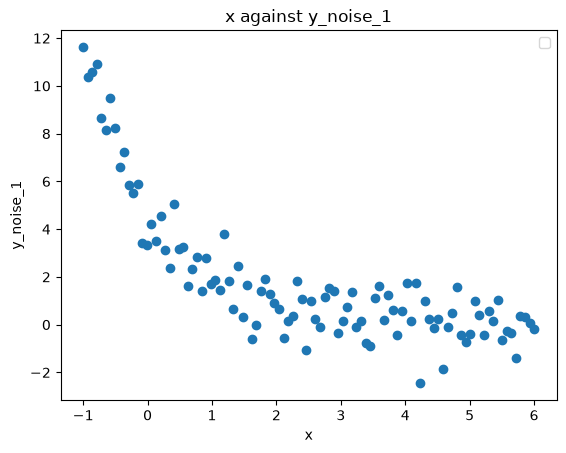

In [18]:
df = pd.read_csv("/home/nvanoosting/Documents/python_decal_fa26/course_assignments/homework9/noisy_curvefit_data.csv")

df.shape # (100, 6), 100 rows, 6 columns

print(df.head(),
      df.tail()
     )

# Column Names: x, y_noise_1, y_noise_2, y_noise_3, y_noise_4, y_noise_5

plt.scatter(df["x"], df["y_noise_1"])
plt.xlabel("x")
plt.ylabel("y_noise_1")
plt.title("x against y_noise_1")
plt.legend()
plt.show()

Fit: y = 4.71 * e^(-0.92 * x)


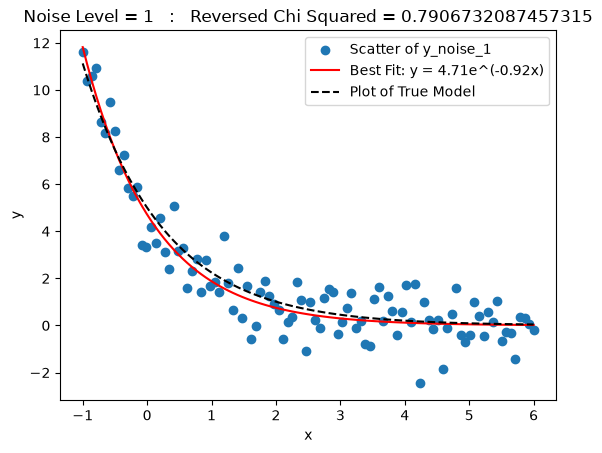

In [29]:
def model(x, A, k):
    return A * np.exp(-k * x)

p0 = [1, 1]

popt, pcov = curve_fit(model, df["x"], df["y_noise_1"], p0=p0)
A_fit, k_fit = popt
print(f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)")

residuals = df["y_noise_1"] - model(df["x"], A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(df["x"]) - len(popt)
chi2_reduced = chi2 / dof

plt.scatter(df["x"], df["y_noise_1"], label = "Scatter of y_noise_1")

plt.plot(df["x"], 4.71 * np.e ** (-0.92 * df["x"]), color = "red", label = f"Best Fit: y = {A_fit:.2f}e^(-{k_fit:.2f}x)")

plt.plot(df["x"], model(df["x"], 5, 0.8), linestyle = "--", color = "black", label = "Plot of True Model")

plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Noise Level = 1   :   Reversed Chi Squared = {chi2_reduced}")
plt.legend()
plt.show()

In [41]:
def fit_model(x, y):
    popt, pcov = curve_fit(model, x, y, p0=p0)
    A_fit, k_fit = popt
    residuals = y - model(x, A_fit, k_fit)
    chi2 = np.sum(residuals**2)
    dof = len(x) - len(popt)
    chi2_reduced = chi2 / dof
    return A_fit, k_fit, chi2_reduced

fig, axes = plt.subplots(2, 2)

axes[0, 0].scatter(df["x"], df["y_noise_2"], label = "Scatter of y_noise_2")
axes[0, 0].plot(df["x"], fit_model(df["x"], df["y_noise_2"])[0] * np.e ** (-fit_model(df["x"], df["y_noise_2"])[1] * df["x"]), color = "red", label = f"Best Fit: y = {fit_model(df["x"], df["y_noise_2"])[0]:.2f}e^(-{fit_model(df["x"], df["y_noise_2"])[1]:.2f}x)")
axes[0, 0].plot(df["x"], model(df["x"], 5, 0.8), linestyle = "--", color = "black", label = "plot of true model")
axes[0, 0].set_xlabel("x")
axes[0, 0].set_ylabel("y")
axes[0, 0].set_title(f"Noise Level = 2   :  Chi Squared Reduced = {fit_model(df['x'], df['y_noise_2'])[2]}")
axes[0, 0].legend()
    
axes[0, 1].scatter(df["x"], df["y_noise_3"], label = "Scatter of y_noise_3")
axes[0, 1].plot(df["x"], fit_model(df["x"], df["y_noise_3"])[0] * np.e ** (-fit_model(df["x"], df["y_noise_3"])[1] * df["x"]), color = "red", label = f"Best Fit: y = {fit_model(df["x"], df["y_noise_3"])[0]:.2f}e^(-{fit_model(df["x"], df["y_noise_3"])[1]:.2f}x)")
axes[0, 1].plot(df["x"], model(df["x"], 5, 0.8), linestyle = "--", color = "black", label = "plot of true model")
axes[0, 1].set_xlabel("x")
axes[0, 1].set_ylabel("y")
axes[0, 1].set_title(f"Noise Level = 3   :  Chi Squared Reduced = {fit_model(df["x"], df["y_noise_3"])[2]}")
axes[0, 1].legend()

axes[1, 0].scatter(df["x"], df["y_noise_4"], label = "Scatter of y_noise_4")
axes[1, 0].plot(df["x"], fit_model(df["x"], df["y_noise_4"])[0] * np.e ** (-fit_model(df["x"], df["y_noise_4"])[1] * df["x"]), color = "red", label = f"Best Fit: y = {fit_model(df["x"], df["y_noise_4"])[0]:.2f}e^(-{fit_model(df["x"], df["y_noise_4"])[1]:.2f}x)")
axes[1, 0].plot(df["x"], model(df["x"], 5, 0.8), linestyle = "--", color = "black", label = "plot of true model")
axes[1, 0].set_xlabel("x")
axes[1, 0].set_ylabel("y")
axes[1, 0].set_title(f"Noise Level = 4   :  Chi Squared Reduced = {fit_model(df["x"], df["y_noise_4"])[2]}"
axes[1, 0].legend()

axes[1, 1].scatter(df["x"], df["y_noise_5"], label = "Scatter of y_noise_5")
axes[1, 1].plot(df["x"], fit_model(df["x"], df["y_noise_5"])[0] * np.e ** (-fit_model(df["x"], df["y_noise_5"])[1] * df["x"]), color = "red", label = f"Best Fit: y = {fit_model(df["x"], df["y_noise_5"])[0]:.2f}e^(-{fit_model(df["x"], df["y_noise_5"])[1]:.2f}x)")
axes[1, 1].plot(df["x"], model(df["x"], 5, 0.8), linestyle = "--", color = "black", label = "plot of true model")
axes[1, 1].set_xlabel("x")
axes[1, 1].set_ylabel("y")
axes[1, 1].set_title(f"Noise Level = 5   :  Chi Squared Reduced = {fit_model(df["x"], df["y_noise_5"])[2]}"
axes[1, 1].legend()

plt.show()


SyntaxError: invalid syntax. Perhaps you forgot a comma? (2258552573.py, line 33)